In [2]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv('tabela_final.csv')

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4009 entries, 0 to 4008
Data columns (total 8 columns):
 #   Column                                   Non-Null Count  Dtype  
---  ------                                   --------------  -----  
 0   Ano_do_Censo                             4009 non-null   int64  
 1   Nome_do_Municipio                        4009 non-null   object 
 2   Codigo_da_Escola                         4009 non-null   int64  
 3   Nome_da_Escola                           4009 non-null   object 
 4   Quantidade_de_Matriculados_Ensino_Medio  4009 non-null   float64
 5   Aprovacao_EM_Total                       4009 non-null   float64
 6   Reprovacao_EM_Total                      4009 non-null   float64
 7   Abandono_EM_Total                        4009 non-null   float64
dtypes: float64(4), int64(2), object(2)
memory usage: 250.7+ KB


In [5]:
#checando se há valores nulos
df.isna().sum()

,0
Ano_do_Censo,0
Nome_do_Municipio,0
Codigo_da_Escola,0
Nome_da_Escola,0
Quantidade_de_Matriculados_Ensino_Medio,0
Aprovacao_EM_Total,0
Reprovacao_EM_Total,0
Abandono_EM_Total,0


In [6]:
#checando se há duplicatas
df.duplicated().sum()

np.int64(0)

In [7]:
#checando os valores únicos
df['Ano_do_Censo'].unique()


array([2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2015, 2016, 2025])

In [8]:
df.describe()

,Ano_do_Censo,Codigo_da_Escola,Quantidade_de_Matriculados_Ensino_Medio,Aprovacao_EM_Total,Reprovacao_EM_Total,Abandono_EM_Total
count,4009.000000,4.009000e+03,4009.000000,4009.000000,4009.000000,4009.000000
mean,2020.007234,3.309524e+07,513.982040,77.664405,14.790422,7.545173
std,3.165621,5.549851e+04,520.913534,13.176567,9.987367,8.331654
min,2015.000000,3.305188e+07,2.000000,0.000000,0.000000,0.000000
25%,2017.000000,3.307159e+07,162.000000,68.500000,7.200000,0.700000
50%,2020.000000,3.308643e+07,294.000000,77.900000,14.100000,5.200000
75%,2023.000000,3.310464e+07,671.000000,87.600000,20.800000,11.500000
max,2025.000000,3.355823e+07,2805.000000,100.000000,80.600000,100.000000


##Gráficos e outliers

In [9]:
abandono_municipio = (
    df.groupby('Nome_do_Municipio')['Abandono_EM_Total']
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)



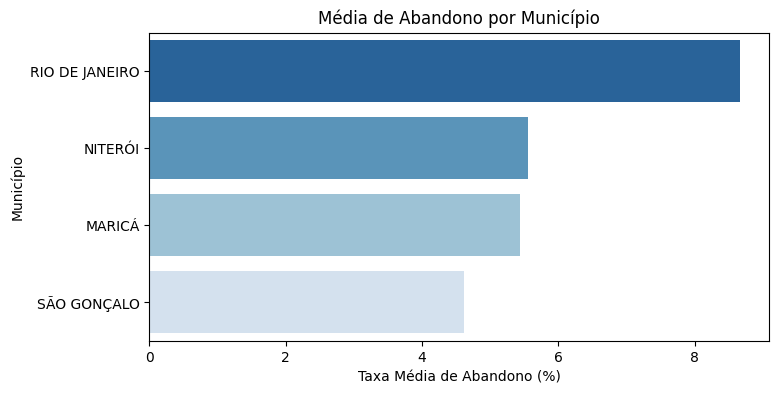

In [10]:
#gráfico de média de abandono por município
plt.figure(figsize=(8, 4))
sns.barplot(
    data=abandono_municipio,
    y='Nome_do_Municipio',
    x='Abandono_EM_Total',
    hue='Nome_do_Municipio',
    palette='Blues_r',
    legend=False)
plt.title('Média de Abandono por Município')
plt.xlabel('Taxa Média de Abandono (%)')
plt.ylabel('Município')
plt.show()

In [11]:
abandono_por_ano = (
    df.groupby('Ano_do_Censo')['Abandono_EM_Total']
      .mean()
      .reset_index()
)
display(abandono_por_ano)

,Ano_do_Censo,Abandono_EM_Total
0,2015,7.714601
1,2016,13.020000
2,2017,7.467751
3,2018,8.020811
4,2019,10.891086
5,2020,0.602479
6,2021,2.939118
7,2022,9.836364
8,2023,8.336639
9,2024,8.182337


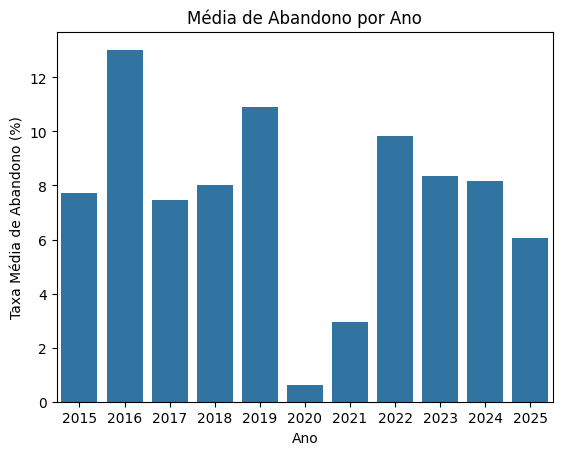

In [12]:
#média de abandono por ano
sns.barplot(abandono_por_ano, x='Ano_do_Censo', y='Abandono_EM_Total' )
plt.title('Média de Abandono por Ano')
plt.xlabel('Ano')
plt.ylabel('Taxa Média de Abandono (%)')
plt.show()

In [13]:
aprovacao_por_ano = (
    df.groupby('Ano_do_Censo')['Aprovacao_EM_Total']
      .mean()
      .reset_index()
)
display(aprovacao_por_ano)

,Ano_do_Censo,Aprovacao_EM_Total
0,2015,75.681818
1,2016,66.609167
2,2017,74.187534
3,2018,73.178378
4,2019,72.383287
5,2020,88.072727
6,2021,90.367218
7,2022,73.779339
8,2023,75.171350
9,2024,75.929076


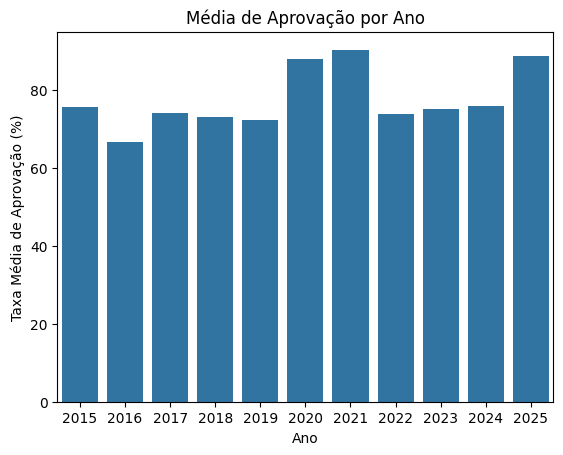

In [14]:
#média de aprovação por ano
sns.barplot(aprovacao_por_ano, x='Ano_do_Censo', y='Aprovacao_EM_Total' )
plt.title('Média de Aprovação por Ano')
plt.xlabel('Ano')
plt.ylabel('Taxa Média de Aprovação (%)')
plt.show()

In [15]:
#checando quantos registros temos por município
df['Nome_do_Municipio'].value_counts()

,count
Nome_do_Municipio,
RIO DE JANEIRO,2795
SÃO GONÇALO,729
NITERÓI,382
MARICÁ,103


In [16]:
reprovacao_por_ano = (
    df.groupby('Ano_do_Censo')['Reprovacao_EM_Total']
      .mean()
      .reset_index()
)
display(reprovacao_por_ano)

,Ano_do_Censo,Reprovacao_EM_Total
0,2015,16.603581
1,2016,20.370833
2,2017,18.344715
3,2018,18.800811
4,2019,16.725627
5,2020,11.324793
6,2021,6.693664
7,2022,16.384298
8,2023,16.492011
9,2024,15.888587


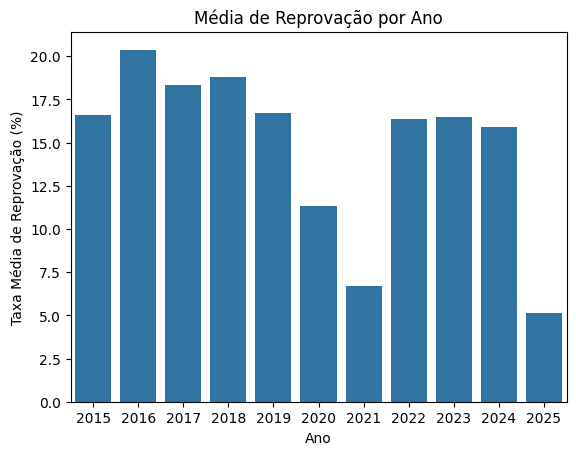

In [17]:
#média de aprovação por ano
sns.barplot(reprovacao_por_ano, x='Ano_do_Censo', y='Reprovacao_EM_Total' )
plt.title('Média de Reprovação por Ano')
plt.xlabel('Ano')
plt.ylabel('Taxa Média de Reprovação (%)')
plt.show()